# Part C: neural networks trained from scratch

Every decision is made on val. Each step keeps the winner of the previous step and changes one thing, which gives 20 trainings instead of a full grid of about 70.

1. Vocabulary and embeddings
2. Models
3. Embeddings, on C1
4. C2, C3 and C4
5. Preprocessing ablation
6. Class imbalance and thresholds
7. Polarity conditioned on the aspect
8. Seeds of the final models
9. Attention weights
10. Full pipeline on val


**Running this notebook.** Each model has its own cell, and a finished run is saved on Drive. If a cell fails, rerun only that cell. After a lost session, run the notebook again: finished runs reload in seconds. To train one again, pass `retrain=True` in its cell.

## Setup

In [3]:
import os
import sys
from google.colab import drive
drive.mount("/content/drive")

REPO = "AR-aspect-sentiment"

if not os.path.exists(f"/content/{REPO}"):
    !git clone https://github.com/cad0m/{REPO}.git /content/{REPO}
else:
    !git -C /content/{REPO} pull

%cd /content/{REPO}

if f"/content/{REPO}" not in sys.path:
    sys.path.insert(0, f"/content/{REPO}")

!pip install -q arabert emoji gensim sentencepiece tashaphyne

OUTPUT_DIR = f"/content/drive/MyDrive/{REPO}"
os.environ["OUTPUT_DIR"] = OUTPUT_DIR
!mkdir -p {OUTPUT_DIR} && cp -rn results {OUTPUT_DIR}/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Cloning into '/content/AR-aspect-sentiment'...
remote: Enumerating objects: 83, done.
remote: Counting objects: 100% (83/83), done.
remote: Compressing objects: 100% (59/59), done.
remote: Total 83 (delta 30), reused 62 (delta 19), pack-reused 0 (from 0)
Receiving objects: 100% (83/83), 4.53 MiB | 17.10 MiB/s, done.
Resolving deltas: 100% (30/30), done.
/content/AR-aspect-sentiment
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead


In [4]:
import math
import shutil
import tempfile
from collections import Counter
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import seaborn as sns
import torch
from gensim.models import Word2Vec
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence
from torch.utils.data import DataLoader, WeightedRandomSampler
from tqdm.auto import tqdm

from src.aspect_names import OPINION_WORDS
from src.data import POLARITIES, category_list, category_matrix, load_test, load_train_val, pair_units, pairs
from src.evaluation import (
    THRESHOLD_GRID,
    accuracy_by_mixed_sentence,
    best_category_thresholds,
    best_global_threshold,
    category_report,
    category_scores,
    compare_threshold_policies,
    pairs_from_matrix,
    pipeline_outcomes,
    pipeline_scores,
    polarity_f1_by_class,
    polarity_scores,
    predict_labels,
)
from src.plots import (
    plot_category_f1,
    plot_f1_by_threshold,
    plot_grouped_bars,
    plot_mixed_accuracy,
    plot_model_comparison,
    plot_pipeline_outcomes,
    plot_polarity_confusion,
    plot_polarity_f1,
    plot_threshold_policies,
    plot_training_curves,
    show_attention,
)
from src.preprocessing import NORM_STEPS, build_pipeline
from src.tracking import best_of_each_model, cached_run, latency_ms, log_results, result_row, save_scores
from src.training import DEVICE, collect_outputs, compact_state, fit, set_seed

SEED = 42
sns.set_theme(style="whitegrid", context="notebook")
print("Device:", DEVICE)

Device: cuda


In [5]:
MIN_FREQUENCY = 2
MAX_WORDS = 70
MAX_CHARS = 380

EMBEDDING_SIZE = 100
HIDDEN_SIZE = 128
ASPECT_SIZE = 32
D_MODEL = 128
N_HEADS = 4
N_ENCODER_LAYERS = 2
DROPOUT = 0.3

BATCH_SIZE = 32
LEARNING_RATE = 1e-3
PAD = 0
UNK = 1

In [6]:
opinions, train, val = load_train_val(SEED)

classes = category_list(opinions)
train_labels = category_matrix(train.categories, classes)
val_labels = category_matrix(val.categories, classes)

train_pairs = pairs(opinions, train)
val_pairs = pairs(opinions, val)
train_units = pair_units(train_pairs)
train_units = train_units[~train_units.ambiguous].reset_index(drop=True)
val_units = pair_units(val_pairs)
clear_units = ~val_units.ambiguous.to_numpy(dtype=bool)

print(f"{len(train)} train and {len(val)} val sentences, {len(classes)} categories")
print(f"{len(train_units)} train and {len(val_units)} val (sentence, category) pairs")

4301 train and 481 val sentences, 34 categories
8060 train and 930 val (sentence, category) pairs


## 1. Vocabulary and embeddings

The vocabulary is built on train only, with the words seen at least twice. `MAX_WORDS` and `MAX_CHARS` cover 99% of the sentences. Words and characters use the same class, only the splitting changes.

The default preprocessing is `NORM_STEPS`: a word model has no character n-grams to absorb spelling variation, and AraVec applies the same letter normalization. Section 5 tests this choice.

In [7]:
class TextEncoder:
    def __init__(self, texts, steps, split_text, max_length):
        self.prepare_text = build_pipeline(steps)
        self.split_text = split_text
        self.max_length = max_length

        counts = Counter(token for text in texts for token in self.tokens(text))
        kept_tokens = [token for token, count in counts.most_common() if count >= MIN_FREQUENCY]
        self.vocabulary = ["<pad>", "<unk>"] + kept_tokens
        self.token_ids = {token: index for index, token in enumerate(self.vocabulary)}

    def tokens(self, text):
        return self.split_text(self.prepare_text(text))[:self.max_length]

    def encode(self, text):
        return torch.tensor([self.token_ids.get(token, UNK) for token in self.tokens(text)] or [UNK])

    def oov_rates(self, texts):
        tokens = [token for text in texts for token in self.tokens(text)]
        unknown = [token for token in tokens if token not in self.token_ids]
        return {"oov_tokens": len(unknown) / len(tokens), "oov_distinct": len(set(unknown)) / len(set(tokens))}


def make_word_encoder(steps=NORM_STEPS):
    return TextEncoder(train.text, steps, str.split, MAX_WORDS)


def make_char_encoder(steps=NORM_STEPS):
    return TextEncoder(train.text, steps, list, MAX_CHARS)


word_encoder = make_word_encoder()
print(f"{len(word_encoder.vocabulary)} words")
print("OOV on val:", word_encoder.oov_rates(val.text))

6419 words
OOV on val: {'oov_tokens': 0.15664210316669985, 'oov_distinct': 0.39261834715164484}


AraVec 3.0: unigrams, CBOW, 100 dimensions, trained on Twitter, closer to informal reviews than Wikipedia. Words missing from AraVec keep a random vector. The file is about 1 GB, so it stays in the temporary folder of the session.

In [8]:
ARAVEC_NAME = "full_uni_cbow_100_twitter"
aravec_dir = Path(tempfile.gettempdir()) / "aravec"

if not (aravec_dir / f"{ARAVEC_NAME}.mdl").exists():
    archive_path, _ = urlretrieve(f"https://bakrianoo.ewr1.vultrobjects.com/aravec/{ARAVEC_NAME}.zip")
    shutil.unpack_archive(archive_path, aravec_dir, "zip")

aravec = Word2Vec.load(str(aravec_dir / f"{ARAVEC_NAME}.mdl")).wv
aravec_scale = float(aravec.vectors.std())

val_tokens = [token for text in val.text for token in word_encoder.tokens(text)]
print(f"{np.mean([word in aravec for word in word_encoder.vocabulary[2:]]):.1%} of our vocabulary is in AraVec")
print(f"{np.mean([token in aravec for token in val_tokens]):.1%} of val tokens are in AraVec")

97.5% of our vocabulary is in AraVec
97.9% of val tokens are in AraVec


In [9]:
def aravec_matrix(encoder):
    matrix = np.random.default_rng(0).normal(0, aravec_scale, (len(encoder.vocabulary), EMBEDDING_SIZE))
    found = [index for index, word in enumerate(encoder.vocabulary) if word in aravec]
    matrix[found] = aravec[[encoder.vocabulary[index] for index in found]]
    matrix[PAD] = 0
    return torch.tensor(matrix, dtype=torch.float32)


def make_embedding(kind, encoder):
    if kind == "random":
        return nn.Embedding(len(encoder.vocabulary), EMBEDDING_SIZE, padding_idx=PAD)
    return nn.Embedding.from_pretrained(aravec_matrix(encoder), freeze=kind == "aravec frozen", padding_idx=PAD)

## 2. Models

**C1:** the last states of both directions go to 34 sigmoids.

**C2:** the attention is written by hand. A small network gives each word a score, a softmax over the real words turns the scores into weights, and the weighted mean of the BiLSTM states goes to the sigmoids. With a `query`, the score also depends on the aspect, which section 7 uses.

In [10]:
class BiLSTMEncoder(nn.Module):
    def __init__(self, embedding):
        super().__init__()
        self.embedding = embedding
        self.dropout = nn.Dropout(DROPOUT)
        self.lstm = nn.LSTM(EMBEDDING_SIZE, HIDDEN_SIZE, batch_first=True, bidirectional=True)

    def forward(self, tokens):
        mask = tokens != PAD
        lengths = mask.sum(dim=1).cpu()
        packed = pack_padded_sequence(self.dropout(self.embedding(tokens)), lengths, batch_first=True, enforce_sorted=False)
        packed_states, (hidden, _) = self.lstm(packed)
        states, _ = pad_packed_sequence(packed_states, batch_first=True, total_length=tokens.size(1))
        return states, torch.cat([hidden[-2], hidden[-1]], dim=1), mask


class Attention(nn.Module):
    def __init__(self, state_size, query_size=0):
        super().__init__()
        self.projection = nn.Linear(state_size + query_size, state_size)
        self.word_score = nn.Linear(state_size, 1, bias=False)

    def forward(self, states, mask, query=None):
        inputs = states
        if query is not None:
            inputs = torch.cat([states, query.unsqueeze(1).expand(-1, states.size(1), -1)], dim=2)
        word_scores = self.word_score(torch.tanh(self.projection(inputs))).squeeze(2)
        weights = word_scores.masked_fill(~mask, -math.inf).softmax(dim=1)
        return (weights.unsqueeze(2) * states).sum(dim=1), weights


class BiLSTMClassifier(nn.Module):
    def __init__(self, embedding):
        super().__init__()
        self.encoder = BiLSTMEncoder(embedding)
        self.dropout = nn.Dropout(DROPOUT)
        self.classifier = nn.Linear(2 * HIDDEN_SIZE, len(classes))

    def forward(self, tokens):
        _, last_states, _ = self.encoder(tokens)
        return self.classifier(self.dropout(last_states))


class AttentionClassifier(nn.Module):
    def __init__(self, embedding):
        super().__init__()
        self.encoder = BiLSTMEncoder(embedding)
        self.attention = Attention(2 * HIDDEN_SIZE)
        self.dropout = nn.Dropout(DROPOUT)
        self.classifier = nn.Linear(2 * HIDDEN_SIZE, len(classes))

    def encode(self, tokens):
        states, _, mask = self.encoder(tokens)
        return self.attention(states, mask)

    def forward(self, tokens):
        summary, _ = self.encode(tokens)
        return self.classifier(self.dropout(summary))

**C3:** Transformer encoder with 2 layers, `d_model` 128 and 4 heads, then the mean of the word states. **C4:** convolutions of widths 3, 4, 5 and 7 over characters.

In [11]:
class PositionalEncoding(nn.Module):
    def __init__(self):
        super().__init__()
        positions = torch.arange(MAX_WORDS).unsqueeze(1)
        frequencies = torch.exp(torch.arange(0, D_MODEL, 2) * (-math.log(10000.0) / D_MODEL))
        table = torch.zeros(MAX_WORDS, D_MODEL)
        table[:, 0::2] = torch.sin(positions * frequencies)
        table[:, 1::2] = torch.cos(positions * frequencies)
        self.register_buffer("table", table)

    def forward(self, states):
        return states + self.table[:states.size(1)]


class TransformerClassifier(nn.Module):
    def __init__(self, embedding, use_positions=True):
        super().__init__()
        self.embedding = embedding
        self.projection = nn.Linear(EMBEDDING_SIZE, D_MODEL)
        self.positions = PositionalEncoding() if use_positions else nn.Identity()
        layer = nn.TransformerEncoderLayer(D_MODEL, N_HEADS, dim_feedforward=2 * D_MODEL, dropout=DROPOUT, batch_first=True)
        self.transformer = nn.TransformerEncoder(layer, N_ENCODER_LAYERS, enable_nested_tensor=False)
        self.dropout = nn.Dropout(DROPOUT)
        self.classifier = nn.Linear(D_MODEL, len(classes))

    def forward(self, tokens):
        mask = tokens != PAD
        states = self.positions(self.projection(self.embedding(tokens)))
        states = self.transformer(states, src_key_padding_mask=~mask)
        mean_state = (states * mask.unsqueeze(2)).sum(dim=1) / mask.sum(dim=1, keepdim=True)
        return self.classifier(self.dropout(mean_state))


class CharCNNClassifier(nn.Module):
    def __init__(self, n_characters, embedding_size=64, n_filters=128, widths=(3, 4, 5, 7)):
        super().__init__()
        self.embedding = nn.Embedding(n_characters, embedding_size, padding_idx=PAD)
        self.convolutions = nn.ModuleList(nn.Conv1d(embedding_size, n_filters, width) for width in widths)
        self.padding = max(widths) - 1
        self.dropout = nn.Dropout(DROPOUT)
        self.classifier = nn.Linear(n_filters * len(widths), len(classes))

    def forward(self, tokens):
        embedded = nn.functional.pad(self.embedding(tokens).transpose(1, 2), (0, self.padding))
        features = [convolution(embedded).relu().amax(dim=2) for convolution in self.convolutions]
        return self.classifier(self.dropout(torch.cat(features, dim=1)))

### Training a category model

Binary cross-entropy on the 34 sigmoids, and early stopping on the best micro-F1 of val. A run is scored with one global threshold, and section 6 compares the threshold policies.

In [12]:
def collate(items):
    batch = {"tokens": pad_sequence([item["tokens"] for item in items], batch_first=True, padding_value=PAD)}
    for name in items[0].keys() - {"tokens"}:
        batch[name] = torch.stack([item[name] for item in items])
    return batch


def make_loader(items, shuffle=False, sampler=None):
    return DataLoader(items, batch_size=BATCH_SIZE, shuffle=shuffle, sampler=sampler, collate_fn=collate)


def category_items(sentence_table, labels, encoder):
    label_rows = torch.tensor(labels, dtype=torch.float32)
    return [{"tokens": encoder.encode(text), "labels": label_row} for text, label_row in zip(sentence_table.text, label_rows)]


def category_probabilities(model, loader):
    return collect_outputs(loader, lambda batch: model(batch["tokens"])).sigmoid().numpy()


def trainable_parameters(model):
    return [parameter for parameter in model.parameters() if parameter.requires_grad]


def run_category(run_name, name, build_model, make_encoder=make_word_encoder, params="none", steps=NORM_STEPS,
                 preprocessing="norm", seed=SEED, pos_weight=None, sampler=None, retrain=False):
    encoder = make_encoder(steps)
    val_loader = make_loader(category_items(val, val_labels, encoder))

    def train_model():
        set_seed(seed)
        model = build_model(encoder).to(DEVICE)
        loss_function = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
        history = fit(
            model,
            make_loader(category_items(train, train_labels, encoder), shuffle=sampler is None, sampler=sampler),
            lambda model, batch: loss_function(model(batch["tokens"]), batch["labels"]),
            lambda model: best_global_threshold(category_probabilities(model, val_loader), val_labels)[1].max(),
            torch.optim.AdamW(trainable_parameters(model), lr=LEARNING_RATE),
        )
        return {"state": compact_state(model), "scores": category_probabilities(model, val_loader), "history": history}

    run = cached_run(f"{run_name}_seed{seed}", train_model, retrain)
    threshold, _ = best_global_threshold(run["scores"], val_labels)
    result = category_scores(val_labels, predict_labels(run["scores"], threshold))
    fit_time = run["history"][-1]["seconds"]
    log_results([result_row("category", name, preprocessing, params, "global", fit_time, seed=seed, **result)])
    print(f"{name} | {params} | {preprocessing}: micro-F1 {result['micro_f1']:.4f}, macro-F1 {result['macro_f1']:.4f}, {fit_time:.0f}s")
    return {"name": name, "params": params, "fit_time_s": fit_time, "encoder": encoder, "build_model": build_model,
            "make_encoder": make_encoder, "pos_weight": pos_weight, "sampler": sampler, **run, **result}


def compare_runs(experiments, title, labels):
    table = pd.DataFrame({"name": labels, "micro_f1": [experiment["micro_f1"] for experiment in experiments]})
    plot_model_comparison(table, "micro_f1", title=title)
    plot_training_curves({label: experiment["history"] for label, experiment in zip(labels, experiments)}, title, "best micro-F1 on val")


def bilstm(embedding_kind):
    return lambda encoder: BiLSTMClassifier(make_embedding(embedding_kind, encoder))


def bilstm_attention(embedding_kind):
    return lambda encoder: AttentionClassifier(make_embedding(embedding_kind, encoder))


def transformer(embedding_kind, use_positions=True):
    return lambda encoder: TransformerClassifier(make_embedding(embedding_kind, encoder), use_positions)


def char_cnn(encoder):
    return CharCNNClassifier(len(encoder.vocabulary))

## 3. Embeddings, on C1

In [13]:
c1_random = run_category("c1_random", "C1 bilstm", bilstm("random"), params="embedding=random")

c1_random_seed42: loaded from disk
C1 bilstm | embedding=random | norm: micro-F1 0.5107, macro-F1 0.1628, 31s


In [14]:
c1_frozen = run_category("c1_frozen", "C1 bilstm", bilstm("aravec frozen"), params="embedding=aravec frozen")

c1_frozen_seed42: loaded from disk
C1 bilstm | embedding=aravec frozen | norm: micro-F1 0.5769, macro-F1 0.2571, 28s


In [15]:
c1_unfrozen = run_category("c1_unfrozen", "C1 bilstm", bilstm("aravec unfrozen"), params="embedding=aravec unfrozen")

c1_unfrozen_seed42: loaded from disk
C1 bilstm | embedding=aravec unfrozen | norm: micro-F1 0.5849, macro-F1 0.2295, 30s


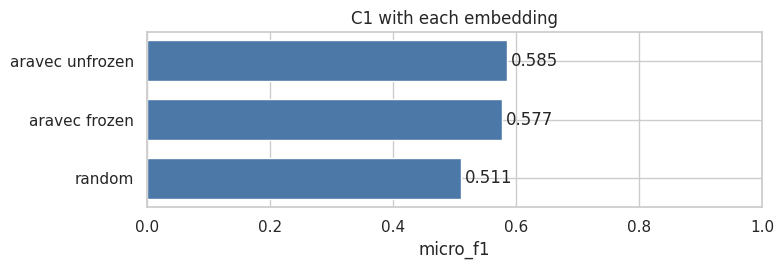

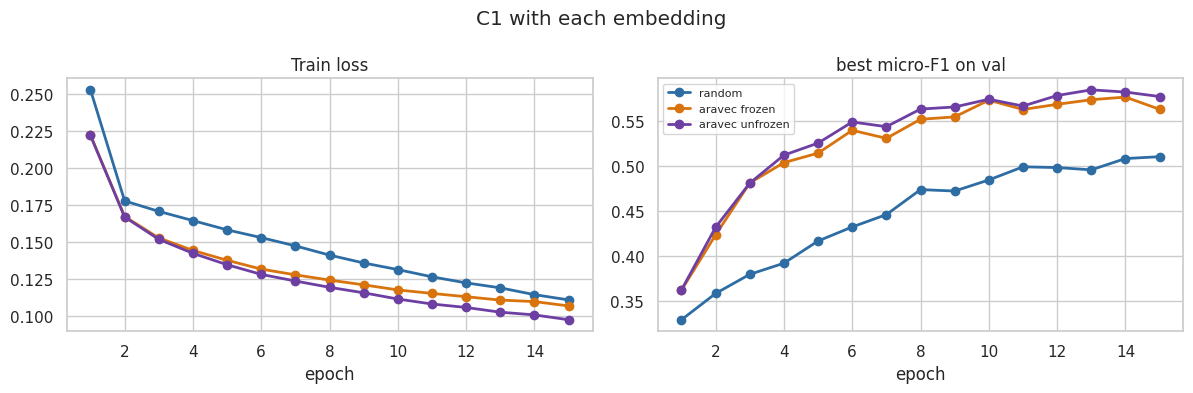

Best embedding: aravec unfrozen


In [16]:
embedding_runs = {"random": c1_random, "aravec frozen": c1_frozen, "aravec unfrozen": c1_unfrozen}
compare_runs(list(embedding_runs.values()), "C1 with each embedding", list(embedding_runs))

best_embedding = max(embedding_runs, key=lambda kind: embedding_runs[kind]["micro_f1"])
print("Best embedding:", best_embedding)

**Conclusions (Q7)**

_To fill in after the run: what AraVec brings, frozen and unfrozen._

## 4. C2, C3 and C4

With the best embedding. Without positional encoding the Transformer sees a bag of words, so this ablation shows how much word order matters.

In [17]:
c2_attention = run_category("c2", "C2 bilstm+attention", bilstm_attention(best_embedding), params=f"embedding={best_embedding}")

c2_seed42: loaded from disk
C2 bilstm+attention | embedding=aravec unfrozen | norm: micro-F1 0.5983, macro-F1 0.2760, 36s


In [18]:
c3_transformer = run_category("c3", "C3 transformer", transformer(best_embedding), params=f"embedding={best_embedding}")

c3_seed42: loaded from disk
C3 transformer | embedding=aravec unfrozen | norm: micro-F1 0.6040, macro-F1 0.2688, 24s


In [19]:
c3_no_positions = run_category("c3_no_positions", "C3 transformer without positions", transformer(best_embedding, use_positions=False),
                               params=f"embedding={best_embedding}")

c3_no_positions_seed42: loaded from disk
C3 transformer without positions | embedding=aravec unfrozen | norm: micro-F1 0.5880, macro-F1 0.2443, 16s


In [20]:
c4_char_cnn = run_category("c4", "C4 char-cnn", char_cnn, make_encoder=make_char_encoder)

c4_seed42: loaded from disk
C4 char-cnn | none | norm: micro-F1 0.6128, macro-F1 0.2836, 19s


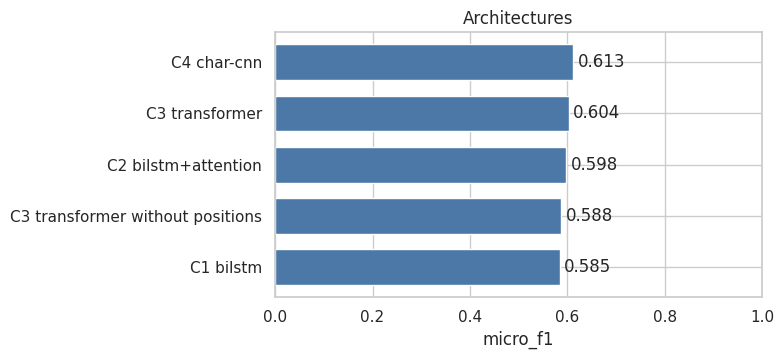

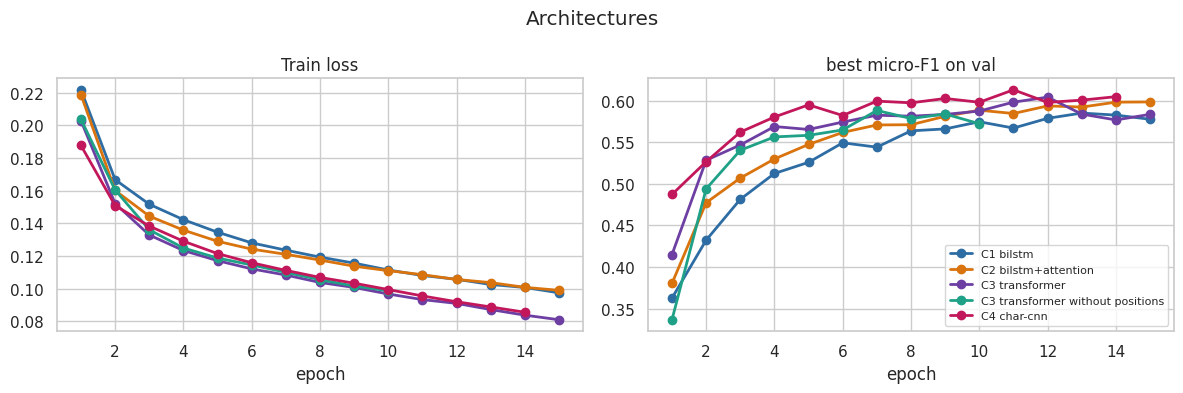

Best model: C4 char-cnn


In [21]:
architecture_runs = [embedding_runs[best_embedding], c2_attention, c3_transformer, c3_no_positions, c4_char_cnn]
compare_runs(architecture_runs, "Architectures", [run["name"] for run in architecture_runs])

best_model = max(architecture_runs, key=lambda run: run["micro_f1"])
print("Best model:", best_model["name"])

**Conclusions (Q7)**

_To fill in after the run: C1 against C2 against C3 and C4, effect of the positional encoding._

## 5. Preprocessing ablation (Q3)

The best model without any preprocessing, then with a single change. A score that rises when a step is removed means the step was destroying information. The last run removes the dialect words instead.

In [22]:
raw_text = run_category("ablation_raw", best_model["name"], best_model["build_model"], best_model["make_encoder"], best_model["params"],
                        steps=[], preprocessing="raw")

ablation_raw_seed42: loaded from disk
C4 char-cnn | none | raw: micro-F1 0.6050, macro-F1 0.3136, 20s


In [23]:
keep_diacritics = run_category("ablation_diacritics", best_model["name"], best_model["build_model"], best_model["make_encoder"], best_model["params"],
                               steps=[step for step in NORM_STEPS if step != "diacritics"], preprocessing="norm, diacritics kept")

ablation_diacritics_seed42: loaded from disk
C4 char-cnn | none | norm, diacritics kept: micro-F1 0.6097, macro-F1 0.2612, 16s


In [24]:
keep_punctuation = run_category("ablation_punctuation", best_model["name"], best_model["build_model"], best_model["make_encoder"], best_model["params"],
                                steps=[step for step in NORM_STEPS if step != "punctuation"], preprocessing="norm, punctuation kept")

ablation_punctuation_seed42: loaded from disk
C4 char-cnn | none | norm, punctuation kept: micro-F1 0.6080, macro-F1 0.2628, 17s


In [25]:
without_dialect = run_category("ablation_dialect", best_model["name"], best_model["build_model"], best_model["make_encoder"], best_model["params"],
                               steps=NORM_STEPS + ["dialect"], preprocessing="norm, dialect words removed")

ablation_dialect_seed42: loaded from disk
C4 char-cnn | none | norm, dialect words removed: micro-F1 0.6004, macro-F1 0.2597, 17s


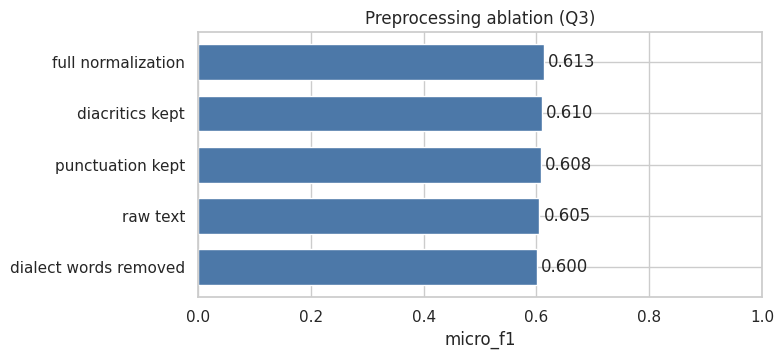

In [26]:
plot_model_comparison(pd.DataFrame({
    "name": ["full normalization", "raw text", "diacritics kept", "punctuation kept", "dialect words removed"],
    "micro_f1": [run["micro_f1"] for run in [best_model, raw_text, keep_diacritics, keep_punctuation, without_dialect]],
}), "micro_f1", title="Preprocessing ablation (Q3)")

**Conclusions (Q3)**

_To fill in after the run: which steps help, which ones destroy clues, and the difference with TF-IDF (0.596 to 0.604 for all preprocessings)._

## 6. Class imbalance and thresholds (Q6)

Two corrections on the best model:

* **Weighted loss:** a positive category weighs `sqrt(negatives / positives)`, because the plain ratio goes over 1000 for rare categories.
* **Oversampling:** on train only, a sentence is drawn more often when it contains a rare category.

In [27]:
positive_counts = train_labels.sum(axis=0).clip(min=1)
pos_weight = torch.tensor(np.sqrt((len(train) - positive_counts) / positive_counts), dtype=torch.float32, device=DEVICE)

weighted_loss = run_category("imbalance_weighted", best_model["name"], best_model["build_model"], best_model["make_encoder"],
                             f"{best_model['params']}, weighted loss", pos_weight=pos_weight)

imbalance_weighted_seed42: loaded from disk
C4 char-cnn | none, weighted loss | norm: micro-F1 0.5768, macro-F1 0.3149, 18s


In [28]:
sentence_weights = (train_labels / np.sqrt(positive_counts)).max(axis=1)
sentence_weights[sentence_weights == 0] = sentence_weights[sentence_weights > 0].min()
oversampler = WeightedRandomSampler(sentence_weights, num_samples=len(train), replacement=True)

oversampling = run_category("imbalance_oversampling", best_model["name"], best_model["build_model"], best_model["make_encoder"],
                            f"{best_model['params']}, oversampling", sampler=oversampler)

imbalance_oversampling_seed42: loaded from disk
C4 char-cnn | none, oversampling | norm: micro-F1 0.5806, macro-F1 0.2811, 12s


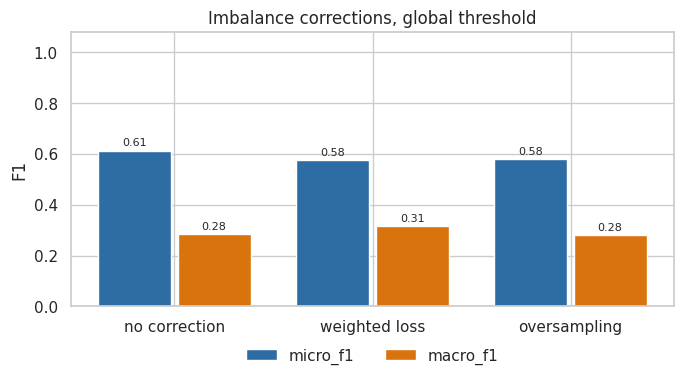

Final setup: no correction


In [29]:
imbalance_runs = {"no correction": best_model, "weighted loss": weighted_loss, "oversampling": oversampling}

plot_grouped_bars(
    pd.DataFrame({name: {"micro_f1": run["micro_f1"], "macro_f1": run["macro_f1"]} for name, run in imbalance_runs.items()}).T,
    "F1", "Imbalance corrections, global threshold",
)

final_setup = max(imbalance_runs, key=lambda name: imbalance_runs[name]["micro_f1"])
final_category = imbalance_runs[final_setup]
print("Final setup:", final_setup)

Global or per-category threshold, tuned on half of the val reviews and scored on the other half:

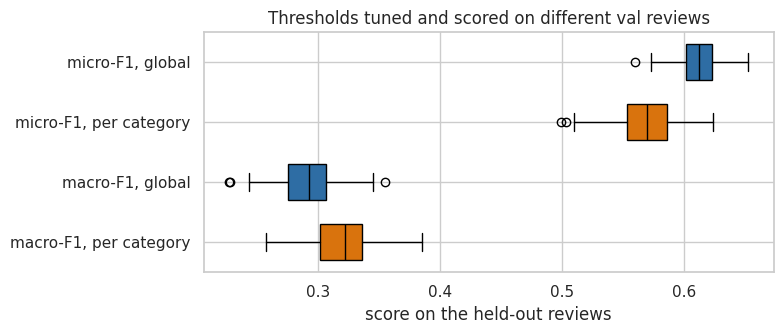

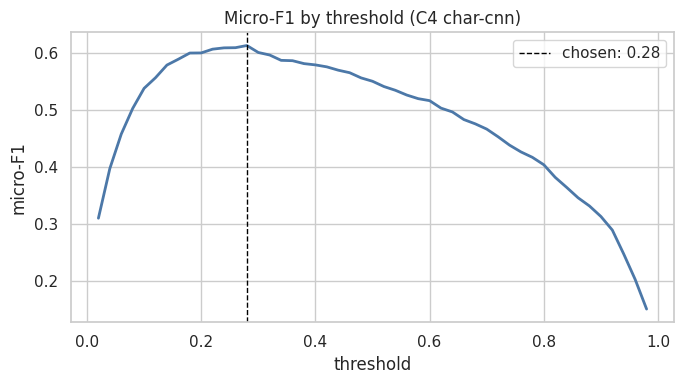

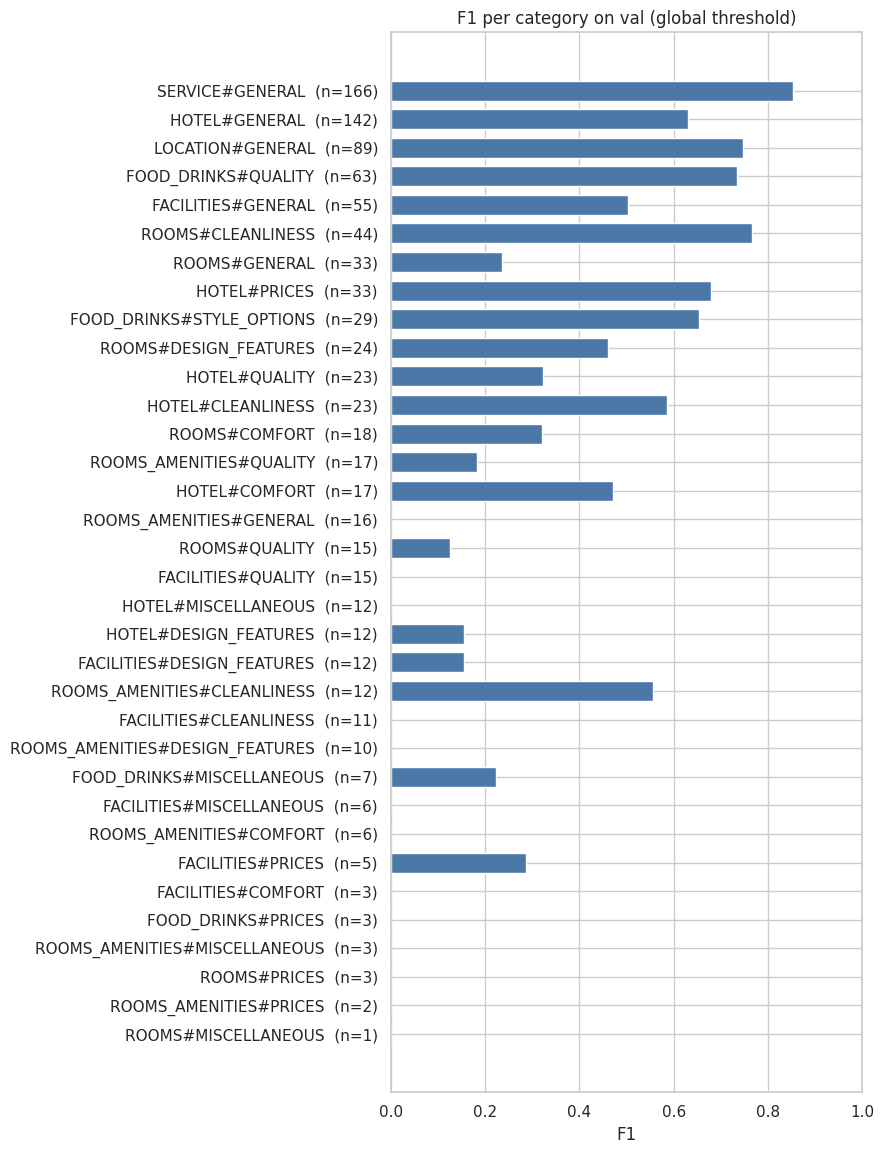

global threshold: 10 categories are never predicted


In [30]:
val_scores = final_category["scores"]
holdout = compare_threshold_policies(val_scores, val_labels, val.review_id, seed=SEED)
plot_threshold_policies(holdout)

global_threshold, f1_curve = best_global_threshold(val_scores, val_labels)
plot_f1_by_threshold(THRESHOLD_GRID, f1_curve, global_threshold, title=f"Micro-F1 by threshold ({final_category['name']})")

use_per_category = holdout.micro_f1_per_category.mean() > holdout.micro_f1_global.mean()
threshold_policy = "per_category" if use_per_category else "global"
chosen_thresholds = best_category_thresholds(val_scores, val_labels, global_threshold) if use_per_category else global_threshold

val_predictions = predict_labels(val_scores, chosen_thresholds)
report = category_report(val_labels, val_predictions, classes)
plot_category_f1(report, title=f"F1 per category on val ({threshold_policy} threshold)")
print(f"{threshold_policy} threshold: {(report.predicted == 0).sum()} categories are never predicted")

**Conclusions (Q6)**

_To fill in after the run: what each correction brings, the threshold policy, and how many categories stay unpredicted (9 for TF-IDF + LR)._

## 7. Polarity conditioned on the aspect

BiLSTM + attention. The category has its own learned vector, used in the attention, so two aspects of one sentence can read different words, and in the classifier, like the one-hot of Part A. The ablation keeps only the classifier.

`balanced` gives each class the same total weight in the loss, so `neutral` is not ignored (Q6).

In [31]:
class AspectPolarityClassifier(nn.Module):
    def __init__(self, embedding, attend_with_aspect=True):
        super().__init__()
        self.encoder = BiLSTMEncoder(embedding)
        self.aspect_embedding = nn.Embedding(len(classes), ASPECT_SIZE)
        self.attention = Attention(2 * HIDDEN_SIZE, ASPECT_SIZE if attend_with_aspect else 0)
        self.attend_with_aspect = attend_with_aspect
        self.dropout = nn.Dropout(DROPOUT)
        self.classifier = nn.Linear(2 * HIDDEN_SIZE + ASPECT_SIZE, len(POLARITIES))

    def encode(self, tokens, aspects):
        states, _, mask = self.encoder(tokens)
        aspect_vectors = self.aspect_embedding(aspects)
        summary, weights = self.attention(states, mask, aspect_vectors if self.attend_with_aspect else None)
        return torch.cat([summary, aspect_vectors], dim=1), weights

    def forward(self, tokens, aspects):
        features, _ = self.encode(tokens, aspects)
        return self.classifier(self.dropout(features))

In [32]:
category_ids = {name: index for index, name in enumerate(classes)}
polarity_ids = {name: index for index, name in enumerate(POLARITIES)}

polarity_counts = train_units.polarity.map(polarity_ids).value_counts().sort_index().to_numpy()
balanced_weights = torch.tensor(len(train_units) / (len(POLARITIES) * polarity_counts), dtype=torch.float32, device=DEVICE)


def pair_items(pair_table):
    """A pair with no single polarity gets the label -1, which is never used for training."""
    aspects = torch.tensor(pair_table.category.map(category_ids).to_numpy())
    labels = torch.tensor(pair_table.polarity.map(polarity_ids).fillna(-1).to_numpy(dtype=int))
    return [
        {"tokens": word_encoder.encode(text), "aspects": aspect, "labels": label}
        for text, aspect, label in zip(pair_table.text, aspects, labels)
    ]


def polarity_outputs(model, loader):
    return collect_outputs(loader, lambda batch: model(batch["tokens"], batch["aspects"]))


def top_polarity(outputs):
    return np.array(POLARITIES, dtype=object)[outputs.argmax(dim=1).numpy()]


polarity_val_loader = make_loader(pair_items(val_units))


def build_polarity_model(attend_with_aspect):
    return AspectPolarityClassifier(make_embedding(best_embedding, word_encoder), attend_with_aspect).to(DEVICE)


def run_polarity(run_name, name, attend_with_aspect, class_weights, seed=SEED, retrain=False):
    def train_model():
        set_seed(seed)
        model = build_polarity_model(attend_with_aspect)
        loss_function = nn.CrossEntropyLoss(weight=class_weights)
        history = fit(
            model,
            make_loader(pair_items(train_units), shuffle=True),
            lambda model, batch: loss_function(model(batch["tokens"], batch["aspects"]), batch["labels"]),
            lambda model: polarity_scores(val_units, top_polarity(polarity_outputs(model, polarity_val_loader)))["macro_f1"],
            torch.optim.AdamW(trainable_parameters(model), lr=LEARNING_RATE),
        )
        return {"state": compact_state(model), "predicted": top_polarity(polarity_outputs(model, polarity_val_loader)), "history": history}

    run = cached_run(f"{run_name}_seed{seed}", train_model, retrain)
    result = polarity_scores(val_units, run["predicted"])
    fit_time = run["history"][-1]["seconds"]
    log_results([result_row("polarity", "bilstm+aspect attention", "norm", f"embedding={best_embedding}, {name}", fit_time_s=fit_time, seed=seed, **result)])
    print(f"{name}: macro-F1 {result['macro_f1']:.4f}, accuracy {result['accuracy']:.4f}, {fit_time:.0f}s")
    return {"name": name, "run_name": run_name, "attend_with_aspect": attend_with_aspect, "class_weights": class_weights, **run, **result}

In [33]:
attention_balanced = run_polarity("polarity_attention_balanced", "aspect in attention, balanced", True, balanced_weights)

polarity_attention_balanced_seed42: loaded from disk
aspect in attention, balanced: macro-F1 0.6765, accuracy 0.8067, 30s


In [34]:
classifier_balanced = run_polarity("polarity_classifier_balanced", "aspect in classifier only, balanced", False, balanced_weights)

polarity_classifier_balanced_seed42: loaded from disk
aspect in classifier only, balanced: macro-F1 0.6624, accuracy 0.7948, 24s


In [35]:
attention_unweighted = run_polarity("polarity_attention_unweighted", "aspect in attention, no weights", True, None)

polarity_attention_unweighted_seed42: loaded from disk
aspect in attention, no weights: macro-F1 0.7021, accuracy 0.8502, 40s


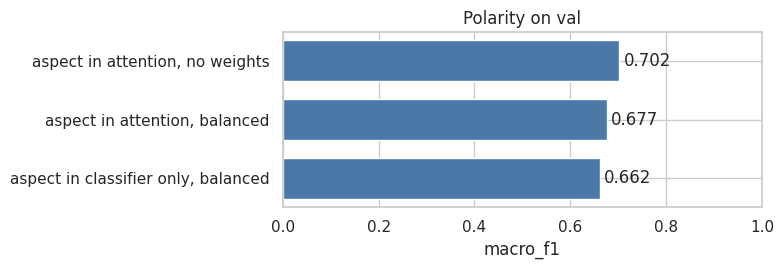

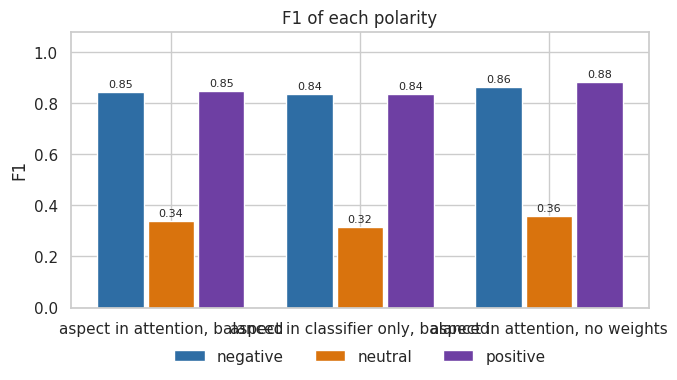

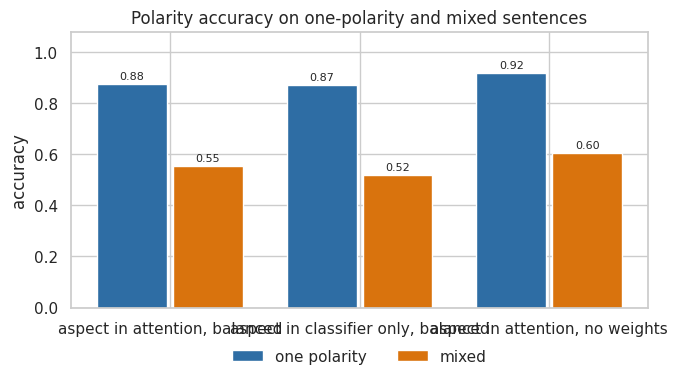

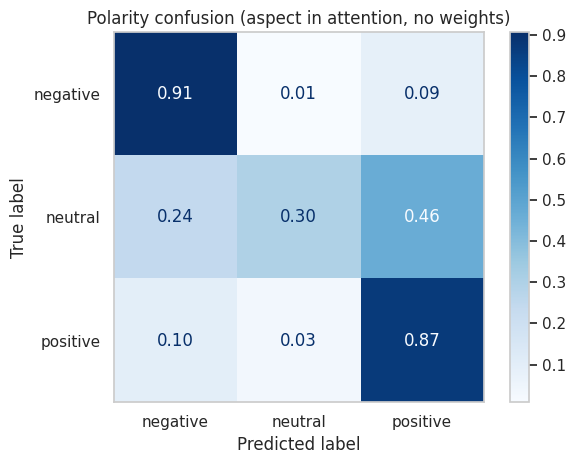

In [36]:
polarity_setups = [attention_balanced, classifier_balanced, attention_unweighted]

plot_model_comparison(pd.DataFrame(polarity_setups), "macro_f1", title="Polarity on val")
plot_polarity_f1({run["name"]: polarity_f1_by_class(val_units, run["predicted"]) for run in polarity_setups})
plot_mixed_accuracy({run["name"]: accuracy_by_mixed_sentence(val_units, run["predicted"]) for run in polarity_setups})

final_polarity = max(polarity_setups, key=lambda run: run["macro_f1"])
val_polarities = final_polarity["predicted"]
plot_polarity_confusion(val_units.polarity[clear_units], val_polarities[clear_units], title=f"Polarity confusion ({final_polarity['name']})")

**Conclusions (Q6, Q7)**

_To fill in after the run: gain of the conditioning on mixed sentences (TF-IDF + LR: 0.610 on mixed, 0.894 on the others), macro-F1 against 0.690, F1 of `neutral`._

## 8. Seeds of the final models

All the choices above used one seed. Two more seeds show how much of a gap is real, and Part F5 needs them.

In [37]:
def repeat_final_category(seed):
    return run_category("final_category", final_category["name"], final_category["build_model"], final_category["make_encoder"],
                        final_category["params"], seed=seed, pos_weight=final_category["pos_weight"], sampler=final_category["sampler"])


def repeat_final_polarity(seed):
    return run_polarity(final_polarity["run_name"], final_polarity["name"], final_polarity["attend_with_aspect"],
                        final_polarity["class_weights"], seed=seed)

In [38]:
category_seed_43 = repeat_final_category(43)

final_category_seed43: loaded from disk
C4 char-cnn | none | norm: micro-F1 0.6132, macro-F1 0.2762, 19s


In [39]:
category_seed_44 = repeat_final_category(44)

final_category_seed44: loaded from disk
C4 char-cnn | none | norm: micro-F1 0.6150, macro-F1 0.2965, 17s


In [40]:
polarity_seed_43 = repeat_final_polarity(43)

polarity_attention_unweighted_seed43: loaded from disk
aspect in attention, no weights: macro-F1 0.7220, accuracy 0.8567, 85s


In [41]:
polarity_seed_44 = repeat_final_polarity(44)

polarity_attention_unweighted_seed44: loaded from disk
aspect in attention, no weights: macro-F1 0.6735, accuracy 0.8360, 57s


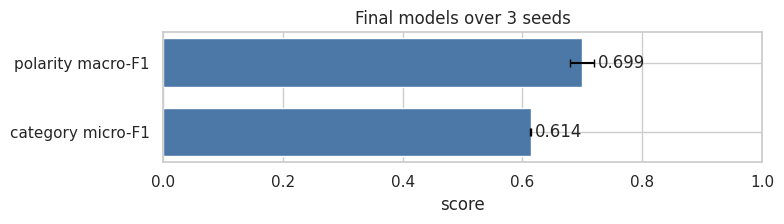

In [42]:
final_category_runs = [final_category, category_seed_43, category_seed_44]
final_polarity_runs = [final_polarity, polarity_seed_43, polarity_seed_44]

category_values = [run["micro_f1"] for run in final_category_runs]
polarity_values = [run["macro_f1"] for run in final_polarity_runs]
plot_model_comparison(pd.DataFrame([
    {"name": "category micro-F1", "score": np.mean(category_values), "std": np.std(category_values)},
    {"name": "polarity macro-F1", "score": np.mean(polarity_values), "std": np.std(polarity_values)},
]), "score", title="Final models over 3 seeds", error="std")

## 9. Attention weights (Q7)

In [43]:
def restore_category_model(run):
    model = run["build_model"](run["encoder"]).to(DEVICE)
    model.load_state_dict(run["state"])
    return model.eval()


def restore_polarity_model(run):
    model = build_polarity_model(run["attend_with_aspect"])
    model.load_state_dict(run["state"])
    return model.eval()


def attention_weights(model, items):
    """One array of weights per item, without the padding."""
    weights = []
    with torch.inference_mode():
        for batch in tqdm(make_loader(items), desc="attention", leave=False):
            inputs = [batch[name].to(DEVICE) for name in ("tokens", "aspects") if name in batch]
            _, batch_weights = model.encode(*inputs)
            lengths = (inputs[0] != PAD).sum(dim=1)
            weights += [row[:length].cpu().numpy() for row, length in zip(batch_weights, lengths)]
    return weights


final_polarity_model = restore_polarity_model(final_polarity)
category_attention = attention_weights(restore_category_model(c2_attention), category_items(val, val_labels, word_encoder))
polarity_attention = attention_weights(final_polarity_model, pair_items(val_units))

val_words = [word_encoder.tokens(text) for text in val.text]
unit_words = [word_encoder.tokens(text) for text in val_units.text]

attention:   0%|          | 0/16 [00:00<?, ?it/s]

attention:   0%|          | 0/30 [00:00<?, ?it/s]

Five mixed sentences. Each aspect has its own line, and darker words get more attention.

In [44]:
units_table = val_units.reset_index(drop=True)
polarities_per_sentence = units_table[~units_table.ambiguous].groupby("sentence_id").polarity.nunique()
shown_rows = units_table.index[units_table.sentence_id.isin(polarities_per_sentence[polarities_per_sentence > 1].index[:5])]

show_attention(
    [unit_words[row] for row in shown_rows],
    [polarity_attention[row] for row in shown_rows],
    [f"{units_table.category[row]}: gold {units_table.polarity[row]}, predicted {val_polarities[row]}" for row in shown_rows],
)

The lift is the attention on a group of words divided by what a uniform attention would give them, so 1 means no focus. Aspect words are the `target` annotations, and implicit aspects are skipped.

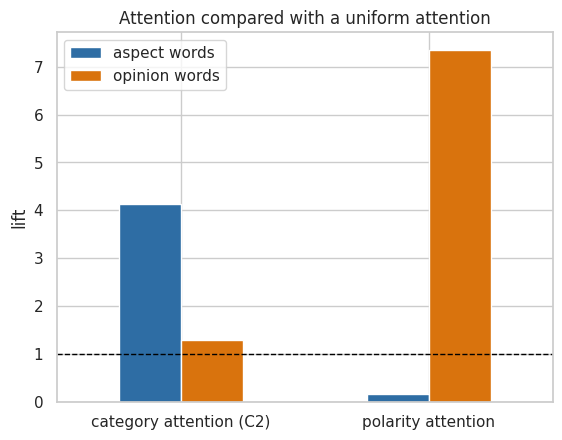

In [45]:
opinion_words = {word_encoder.prepare_text(word) for word in OPINION_WORDS}


def target_word_set(targets):
    return set(" ".join(word_encoder.prepare_text(target) for target in targets).split())


def attention_lift(word_lists, weight_lists, chosen_word_sets):
    lifts = []
    for words, weights, chosen_words in zip(word_lists, weight_lists, chosen_word_sets):
        is_chosen = np.array([word in chosen_words for word in words], dtype=bool)
        if len(words) == len(weights) and 0 < is_chosen.sum() < len(words):
            lifts.append(weights[is_chosen].sum() / is_chosen.mean())
    return float(np.mean(lifts))


explicit_targets = val_pairs[val_pairs.target != "NULL"].dropna(subset=["target"])
targets_by_pair = explicit_targets.groupby(["sentence_id", "category"]).target.agg(target_word_set).to_dict()
targets_by_sentence = explicit_targets.groupby("sentence_id").target.agg(target_word_set).to_dict()
pair_targets = [targets_by_pair.get(key, set()) for key in zip(val_units.sentence_id, val_units.category)]
sentence_targets = [targets_by_sentence.get(sentence_id, set()) for sentence_id in val.sentence_id]

lift_table = pd.DataFrame({
    "aspect words": {
        "category attention (C2)": attention_lift(val_words, category_attention, sentence_targets),
        "polarity attention": attention_lift(unit_words, polarity_attention, pair_targets),
    },
    "opinion words": {
        "category attention (C2)": attention_lift(val_words, category_attention, [opinion_words] * len(val)),
        "polarity attention": attention_lift(unit_words, polarity_attention, [opinion_words] * len(val_units)),
    },
})
axis = lift_table.plot.bar(rot=0, color=["#2E6DA4", "#D9730D"], title="Attention compared with a uniform attention", ylabel="lift")
axis.axhline(1, color="black", linestyle="--", linewidth=1);

**Conclusions (Q7)**

_To fill in after the run: do the weights land on aspect words and opinion adjectives, and do they move between two aspects of one sentence?_

## 10. Full pipeline on val

The final category model finds the pairs, and the final polarity model labels them.

predicting:   0%|          | 0/26 [00:00<?, ?it/s]

/content/AR-aspect-sentiment/src/tracking.py:55: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  table = pd.concat([pd.read_csv(path), table], ignore_index=True)


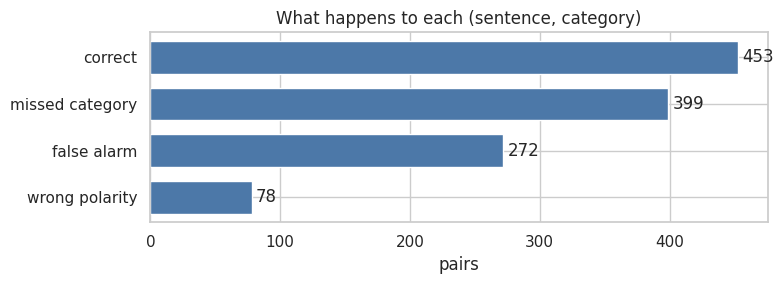

{'category_f1': 0.6128101557991922, 'pipeline_f1': 0.5227928447778419}


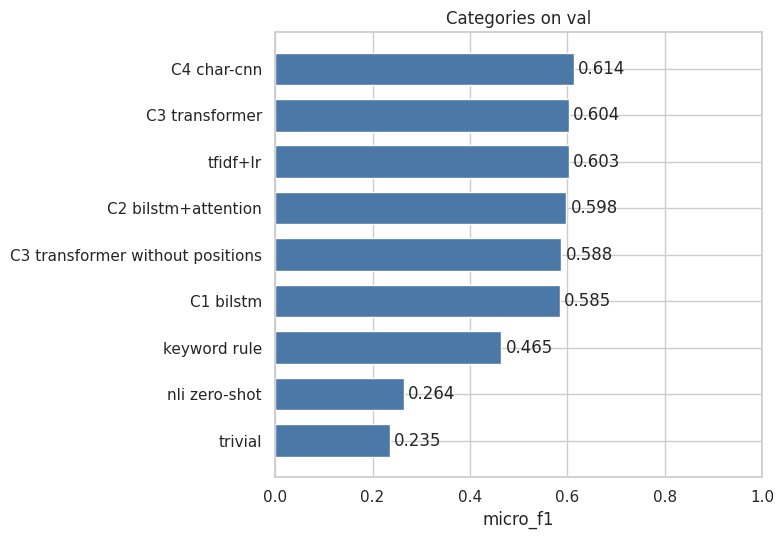

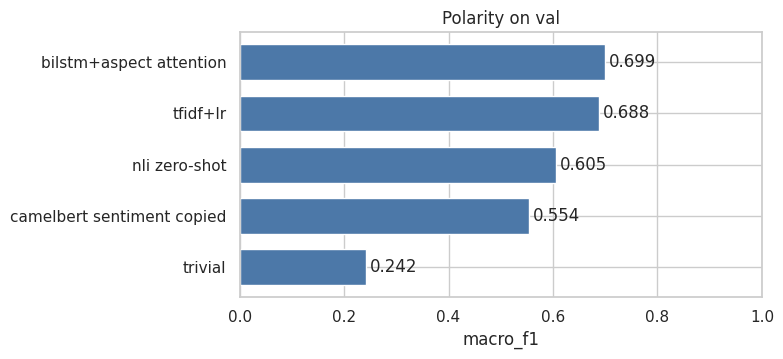

In [46]:
def label_pairs(sentence_table, predictions, polarity_model):
    predicted_pairs = pairs_from_matrix(sentence_table, predictions, classes)
    outputs = polarity_outputs(polarity_model, make_loader(pair_items(predicted_pairs.assign(polarity=None))))
    return predicted_pairs, outputs


predicted_pairs, pair_outputs = label_pairs(val, val_predictions, final_polarity_model)
outcomes = pipeline_outcomes(val_pairs, predicted_pairs.assign(polarity=top_polarity(pair_outputs)))
pipeline_result = pipeline_scores(outcomes)
results = log_results([result_row("pipeline", final_category["name"], "norm", final_category["params"], threshold_policy, micro_f1=pipeline_result["pipeline_f1"])])

plot_pipeline_outcomes(outcomes)
print(pipeline_result)
plot_model_comparison(best_of_each_model(results, "category", "micro_f1"), "micro_f1", title="Categories on val")
plot_model_comparison(best_of_each_model(results, "polarity", "macro_f1"), "macro_f1", title="Polarity on val")

**Conclusions**

_To fill in after the run: neural models against TF-IDF + LR (micro-F1 0.603, polarity macro-F1 0.690, pipeline 0.520), and which step limits the pipeline._

## 11. Save the val scores

In [47]:
thresholds_to_save = np.broadcast_to(chosen_thresholds, len(classes)).tolist()
save_scores("neural_category", "val", val_scores, {"sentence_id": val.sentence_id.to_numpy()}, classes,
            meta={"model": final_category["name"], "params": final_category["params"], "threshold_policy": threshold_policy, "thresholds": thresholds_to_save})

## 12. Test predictions for Part F


Run this section only when the choices above are final. It writes the predictions on the test set for `06_final_test` and prints no score, so nothing here can influence a choice.

In [48]:
test_opinions, test = load_test()
test_units = pair_units(pairs(test_opinions, test))
print("OOV on test:", word_encoder.oov_rates(test.text))


def test_probabilities(run):
    model = restore_category_model(run)
    items = [{"tokens": run["encoder"].encode(text)} for text in test.text]
    return category_probabilities(model, make_loader(items))


def test_polarities(run):
    return polarity_outputs(restore_polarity_model(run), make_loader(pair_items(test_units))).softmax(dim=1).numpy()


test_scores = [test_probabilities(run) for run in final_category_runs]
test_polarity_scores = [test_polarities(run) for run in final_polarity_runs]

OOV on test: {'oov_tokens': 0.16046711036707362, 'oov_distinct': 0.4978029766123317}


predicting:   0%|          | 0/39 [00:00<?, ?it/s]

predicting:   0%|          | 0/39 [00:00<?, ?it/s]

predicting:   0%|          | 0/39 [00:00<?, ?it/s]

predicting:   0%|          | 0/71 [00:00<?, ?it/s]

predicting:   0%|          | 0/71 [00:00<?, ?it/s]

predicting:   0%|          | 0/71 [00:00<?, ?it/s]

In [49]:
test_predictions = predict_labels(test_scores[0], chosen_thresholds)
test_pairs, test_pair_outputs = label_pairs(test, test_predictions, final_polarity_model)

pair_ids = {"sentence_id": test_units.sentence_id.to_numpy(), "category": test_units.category.to_numpy()}
save_scores("neural_polarity", "test", test_polarity_scores, pair_ids, POLARITIES)
save_scores("neural_pipeline", "test", [test_pair_outputs.softmax(dim=1).numpy()],
            {"sentence_id": test_pairs.sentence_id.to_numpy(), "category": test_pairs.category.to_numpy()}, POLARITIES)

predicting:   0%|          | 0/62 [00:00<?, ?it/s]

In [50]:
latency_model = restore_category_model(final_category).cpu()
latency_encoder = final_category["encoder"]


def predict_one_sentence(text):
    with torch.inference_mode():
        return latency_model(latency_encoder.encode(text).unsqueeze(0))


save_scores("neural_category", "test", test_scores, {"sentence_id": test.sentence_id.to_numpy()}, classes, meta={
    "thresholds": thresholds_to_save,
    "train_s": final_category["fit_time_s"],
    "latency_ms": latency_ms(predict_one_sentence, test.text.head(50).tolist()),
    "size_mb": sum(parameter.numel() for parameter in latency_model.parameters()) * 4 / 1e6,
})